# 06. Buffer Allocation Simulator: where should a fixed amount of buffer go?

**Project:** Buffer Delay Allocation Engine (Analytics Capstone Project, Team T19)
**Team:** Vaibhav Maheshwari (BA05057), Prashansa Naomi Konduru (BA05042), Anil Kumar (BA05008)
**Faculty:** Mr. Nikhil D Jonathan
**Data:** `aa_clean_v1.0.parquet` (tag `data-v1.0`): 1,641,071 American Airlines mainline flights, 1 Jan 2025 to 31 Aug 2026

**What this notebook does.** This is the answer to the project's business question: *with a fixed daily budget of extra planned ground time (buffer), which turnarounds should get it,
so that the fewest delay minutes are passed on to later flights?*

We replay the **test period (Jan to Aug 2026)**, which nothing in this notebook was fitted on. For every day we give each strategy the **same budget**, let it decide where to put the buffer
(using only timetable facts), and then use what really happened that day to count how many delay minutes the buffer would have absorbed. The strategies are:

| Strategy | Rule |
|---|---|
| **No buffer** | Reference point: nothing added. |
| **Spread evenly** | Every turnaround gets the same extra minutes. This is the simplest policy. |
| **Shortest first** | Give the maximum to the shortest turnarounds, until the budget runs out. |
| **Riskiest first** | Give the maximum to the turnarounds predicted to arrive latest (Model B from notebook 05). |
| **Engine (our method)** | Put each block of buffer where **(predicted inbound delay) x (minutes the pass-through curve says it absorbs)** is largest. It combines notebooks 04 and 05. |
| **Hindsight (not possible in real life)** | The same rule but using the *real* inbound delays. It shows the best that any strategy could do, so we can see how close the engine gets. |

## How to run this notebook

You need one data file, **`aa_clean_v1.0.parquet`** (68 MB, the cleaned flight data from D2), and these Python packages: pandas, numpy, matplotlib, pyarrow, scikit-learn, lightgbm.
It takes about 3 to 6 minutes and needs about 4 GB of free memory (a normal laptop or free Google Colab is enough). Then choose *Restart and Run All*.

| Where you run it | What to do |
|---|---|
| **Your laptop** (Jupyter, VS Code, Anaconda) | Put `aa_clean_v1.0.parquet` in the same folder as this notebook (or in a folder called `data`). If a package is missing, run `pip install pandas numpy matplotlib pyarrow scikit-learn lightgbm` once. |
| **Google Colab** | Upload this notebook (File, then Upload notebook). Run the first code cell. When it asks, click *Choose files* and select `aa_clean_v1.0.parquet` (or upload the file to the Colab file panel first). Nothing needs to be installed. |

The notebook checks the data file against its published checksum, so you know it is the exact dataset from D2. Charts and tables are saved in a
folder called `modelling_outputs` next to the notebook (or `docs/modelling` if it is run inside the project repository).

## Words used in this notebook

| Word | Meaning |
|---|---|
| **Buffer / budget** | Extra planned ground time, in minutes. The budget is the average number of extra minutes per turnaround that the airline is willing to add (we try 2, 5, 10 and 15). |
| **Absorbed minutes** | Delay minutes that are *not* passed on to the next flight because of the extra ground time. |
| **Pass-through curve** | From notebook 04: the share of an inbound delay still there at departure, for each ground time. |
| **Disruption day** | A day when more than 10% of flights were cancelled (27 days). |
| **95% range** | A range that would contain the true value in 95 of 100 repeats; built by re-drawing whole days at random. |

## 1. Setup and data check

In [1]:
import sys, hashlib, json, warnings
from pathlib import Path

# 1. Check that the packages we need are installed (on Google Colab they already are).
PKGS = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib", "pyarrow": "pyarrow", "sklearn": "scikit-learn", "lightgbm": "lightgbm"}          # import name -> pip name
missing = []
for module, pip_name in PKGS.items():
    try:
        __import__(module)
    except ImportError:
        missing.append(pip_name)
if missing:
    raise ImportError("Please install the missing packages, then run this cell again:\n    pip install " + " ".join(missing))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.labelsize": 10,
                     "legend.frameon": False, "figure.autolayout": True})
BLUE, ORANGE, RED, GREEN, GREY, LIGHT = "#1F3A5F", "#E08A1E", "#C0392B", "#2E8B57", "#8A94A6", "#C9D3E3"
SPLITS = ["train", "validate", "test"]
SEED = 42
RESULTS = {}          # every number we quote is stored here and saved to a .json file at the end
thousands = FuncFormatter(lambda v, pos: f"{v:,.0f}")

# 2. Find the data file: next to the notebook, in 'data' folders, in the Colab file area, or in Downloads.
FILENAME = "aa_clean_v1.0.parquet"
EXPECTED_SHA256 = "3a18a9eafffa77ae74db70579be84255f8b04978efdcdb84524bd2900297f14a"   # published in data/CHECKSUMS.sha256
IN_COLAB = "google.colab" in sys.modules

def locate():
    here = Path.cwd().resolve()
    places = []
    for folder in [here, *here.parents]:
        places += [folder, folder / "data", folder / "data" / "processed"]
    places += [Path("/content"), Path("/content/data"), Path("/content/drive/MyDrive"),
               Path.home() / "Downloads", Path.home() / "Desktop",
               Path("/Volumes/workspace/default/bufferengine/processed")]          # Databricks Volume used by this project
    places += sorted(Path("/Volumes").glob("*/*/*/processed")) if Path("/Volumes").exists() else []   # any other Databricks Volume
    for folder in places:
        if (folder / FILENAME).exists():
            return folder / FILENAME
    return None

PARQUET = locate()
if PARQUET is None and IN_COLAB:
    from google.colab import files
    print(f"Please choose the file {FILENAME} from your computer (68 MB). The upload takes about a minute.")
    files.upload()
    PARQUET = locate()
if PARQUET is None:
    raise FileNotFoundError(f"Could not find {FILENAME}. Put it in the same folder as this notebook (or in a folder called 'data'), "
                            "then run again. On Google Colab, run this cell again and choose the file when asked.")

# 3. Where to save charts and tables.
in_repo = PARQUET.parent.name == "processed" and PARQUET.parent.parent.name == "data" and (PARQUET.parent.parent.parent / "docs").exists()
OUT = (PARQUET.parent.parent.parent / "docs" / "modelling") if in_repo else Path.cwd() / "modelling_outputs"
FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")
    plt.show()

def say(text):
    display(Markdown(text))

def _clean(o):
    if isinstance(o, dict): return {str(k): _clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [_clean(v) for v in o]
    if isinstance(o, np.integer): return int(o)
    if isinstance(o, np.floating): return float(o)
    if isinstance(o, np.bool_): return bool(o)
    return o

def write_results(filename):
    (OUT / filename).write_text(json.dumps(_clean(RESULTS), indent=1))
    print(f"Saved {filename} and {len(list(FIG.glob('*.png')))} chart files in the folder '{OUT.name}'.")

# 4. Make sure this is exactly the published dataset.
actual = hashlib.sha256(PARQUET.read_bytes()).hexdigest()
print("Data file          :", PARQUET.name)
print("Python / pandas    :", sys.version.split()[0], "/", pd.__version__)
print("Checksum matches D2:", actual == EXPECTED_SHA256)
assert actual == EXPECTED_SHA256, "This file is not the published aa_clean_v1.0.parquet (tag data-v1.0). Please download it again."

Data file          : aa_clean_v1.0.parquet
Python / pandas    : 3.13.16 / 3.1.0
Checksum matches D2: True


## Building the turnaround table

A **turnaround** is the stop on the ground between two flights of the same aircraft. The buffer question lives here, so every model in this
project works on one row per turnaround. We rebuild the table directly from `aa_clean_v1.0`, so nothing else is needed.

**In plain words, the code below does five things:**
1. Puts each aircraft's flights in time order.
2. Looks at the aircraft's previous flight for every flight.
3. Keeps the pair only if both flights flew, the first landed where the second takes off, they are on the same day, and the planned gap is above zero.
4. Records the **scheduled ground time** (planned gap in minutes), the **inbound delay** `A` (arrival delay of the first flight) and the **outbound delay** `D` (departure delay of the second flight).
5. Adds facts that are known from the timetable alone (hour, airport, distance, how many flights the aircraft has already flown that day). These are the only things the prediction models are allowed to use.

`A` and `D` are limited to the 0.5% and 99.5% levels of the *training* period, so a few extreme flights cannot dominate the averages.

In [2]:
COLS = ["FlightDate", "Month", "DayOfWeek", "Tail_Number", "Origin", "Dest", "Distance", "crs_dep_min", "crs_arr_min",
        "DepDelay", "ArrDelay", "Cancelled", "Diverted", "is_operated", "crs_dep_utc", "crs_arr_utc", "split"]
df = pd.read_parquet(PARQUET, columns=COLS)
df["FlightDate"] = pd.to_datetime(df["FlightDate"])
print(f"{len(df):,} flights loaded, {df.FlightDate.min().date()} to {df.FlightDate.max().date()}")

# limits for extreme delays, learned on the training period only
cap_lo, cap_hi = df.loc[(df.split == "train") & df.ArrDelay.notna(), "ArrDelay"].quantile([0.005, 0.995]).values
dcap_lo, dcap_hi = df.loc[(df.split == "train") & df.DepDelay.notna(), "DepDelay"].quantile([0.005, 0.995]).values
TOP10 = df.Origin.value_counts().head(10).index.tolist()                     # ten busiest departure airports
daily_cancel = df.groupby("FlightDate").Cancelled.mean()
STORM = set(daily_cancel[daily_cancel > 0.10].index)                          # disruption days: more than 10% of flights cancelled
AIRPORTS = sorted(set(df.Origin) | set(df.Dest))

d = df.loc[df.Tail_Number.notna()].sort_values(["Tail_Number", "crs_dep_utc"]).copy()
day = d.groupby(["Tail_Number", "FlightDate"])
d["legno"] = day.cumcount() + 1                                               # which flight of the aircraft's day this is (timetable fact)
d["mins_since_first"] = d.crs_dep_min - day.crs_dep_min.transform("min")      # minutes since the aircraft's first planned departure of the day
g = d.groupby("Tail_Number", sort=False)
d["prev_dest"] = g["Dest"].shift(); d["prev_origin"] = g["Origin"].shift(); d["prev_dist"] = g["Distance"].shift()
d["prev_arr_utc"] = g["crs_arr_utc"].shift(); d["prev_date"] = g["FlightDate"].shift()
d["prev_dep_hr"] = g["crs_dep_min"].shift() // 60; d["prev_arr_hr"] = g["crs_arr_min"].shift() // 60
d["A_raw"] = g["ArrDelay"].shift()
d["prev_operated"] = g["is_operated"].shift().eq(True); d["prev_notdiv"] = g["Diverted"].shift().eq(0)
d["sg"] = (d.crs_dep_utc - d.prev_arr_utc).dt.total_seconds() / 60            # scheduled ground time in minutes

link = (d.is_operated & (d.Diverted == 0) & d.prev_operated & d.prev_notdiv & (d.prev_dest == d.Origin)
        & (d.sg > 0) & (d.FlightDate == d.prev_date))
T = d.loc[link, ["Tail_Number", "Origin", "prev_origin", "FlightDate", "split", "Month", "DayOfWeek", "crs_dep_min", "sg", "Distance",
                 "prev_dist", "legno", "mins_since_first", "prev_dep_hr", "prev_arr_hr", "A_raw", "DepDelay"]].rename(
    columns={"Origin": "station", "DepDelay": "D_raw"}).dropna(subset=["A_raw", "D_raw"]).copy()
T["A"] = T.A_raw.clip(cap_lo, cap_hi); T["D"] = T.D_raw.clip(dcap_lo, dcap_hi)
T["hr"] = (T.crs_dep_min // 60).clip(0, 23)
T["hub"] = T.station.isin(TOP10).astype(int)
T["storm"] = T.FlightDate.isin(STORM)
for c in ["station", "prev_origin"]:
    T[c] = pd.Categorical(T[c], categories=AIRPORTS)
T = T.reset_index(drop=True)
del d, g, day, link, df                                                       # free memory

print(f"Turnarounds built: {len(T):,}   (disruption days: {len(STORM)}; ten busiest airports: {', '.join(TOP10)})")
display(T.groupby("split").agg(turnarounds=("sg", "size"), first_day=("FlightDate", "min"), last_day=("FlightDate", "max"),
                               median_ground_min=("sg", "median"), mean_inbound_delay=("A", "mean"), mean_outbound_delay=("D", "mean")).loc[SPLITS].round(1))
RESULTS["n_turnarounds"] = int(len(T)); RESULTS["n_storm_days"] = len(STORM); RESULTS["top10"] = TOP10

1,641,071 flights loaded, 2025-01-01 to 2026-08-31


Turnarounds built: 1,060,740   (disruption days: 27; ten busiest airports: DFW, CLT, MIA, ORD, PHX, PHL, LAX, DCA, MCO, LGA)


,turnarounds,first_day,last_day,median_ground_min,mean_inbound_delay,mean_outbound_delay
split,,,,,,
train,474633,2025-01-01,2025-09-30,61.0,5.9,15.9
validate,160835,2025-10-01,2025-12-31,61.0,4.0,13.6
test,425272,2026-01-01,2026-08-31,60.0,4.8,17.0


In [3]:
def _boot(S, B, seed):
    """Re-draw whole days at random, B times, and add up the stored sums (groups x days x stats)."""
    rng = np.random.default_rng(seed)
    nd = S.shape[1]
    idx = rng.integers(0, nd, size=(B, nd))
    return S[:, idx, :].sum(axis=2)

def slope_table(frame, group, labels, B=200, seed=SEED, min_n=300):
    """Pass-through (slope of outbound delay D on inbound delay A) for each group, with a 95% day-block bootstrap range."""
    f = frame[[group, "FlightDate", "A", "D"]].copy()
    f["AA"] = f.A * f.A; f["AD"] = f.A * f.D; f["n"] = 1.0
    days = np.sort(f.FlightDate.unique()); di = pd.Index(days)
    agg = f.groupby([group, "FlightDate"]).agg(n=("n", "sum"), sA=("A", "sum"), sD=("D", "sum"), sAA=("AA", "sum"), sAD=("AD", "sum")).reset_index()
    S = np.zeros((len(labels), len(days), 5))
    S[agg[group].values.astype(int), di.get_indexer(agg.FlightDate), :] = agg[["n", "sA", "sD", "sAA", "sAD"]].values
    def slope(M):
        n, sA, sD, sAA, sAD = [M[..., k] for k in range(5)]
        with np.errstate(divide="ignore", invalid="ignore"):
            return (n * sAD - sA * sD) / (n * sAA - sA ** 2)
    pt = slope(S.sum(axis=1)); bs = slope(_boot(S, B, seed)) if B > 1 else np.full((len(labels), 2), np.nan)
    out = pd.DataFrame({"group": labels, "n": S[..., 0].sum(axis=1).astype(int), "slope": pt,
                        "lo": np.nanpercentile(bs, 2.5, axis=1) if B > 1 else np.nan,
                        "hi": np.nanpercentile(bs, 97.5, axis=1) if B > 1 else np.nan})
    out.loc[out.n < min_n, ["slope", "lo", "hi"]] = np.nan
    return out

## 2. The pass-through curve (learned on the training period)

This is the same curve as in notebook 04, rebuilt here so that this notebook runs on its own. It is learned on **training turnarounds only** (Jan to Sep 2025).

In [4]:
# ---- the pass-through curve, learned on the TRAINING period only ----------------------------------------------------
from sklearn.isotonic import IsotonicRegression

EDGES = [0, 30, 40, 45, 50, 55, 60, 65, 70, 75, 80, 90, 100, 110, 120, 135, 150, 180, 240, 100000]
def edge_label(lo, hi):
    return f"up to {hi}" if lo == 0 else (f"over {lo}" if hi >= 100000 else f"{lo+1}-{hi}")
BIN_LABELS = [edge_label(lo, hi) for lo, hi in zip(EDGES[:-1], EDGES[1:])]

Ptr = T[(T.split == "train") & (T.A > 0)].copy()                 # training turnarounds whose inbound flight was late
Ptr["sgb"] = pd.cut(Ptr.sg, EDGES, labels=False)
raw = slope_table(Ptr, "sgb", BIN_LABELS, B=200)
bin_stats = Ptr.groupby("sgb").agg(sg_mean=("sg", "mean"), A_mean=("A", "mean"), D_mean=("D", "mean")).reindex(range(len(BIN_LABELS)))
raw = pd.concat([raw, bin_stats.reset_index(drop=True)], axis=1)
ok = raw.slope.notna()
# Smooth the curve so that more ground time can never make things worse (a falling line), weighting by group size
iso = IsotonicRegression(increasing=False, y_min=0.0, y_max=1.0, out_of_bounds="clip")
iso.fit(raw.loc[ok, "sg_mean"], raw.loc[ok, "slope"], sample_weight=raw.loc[ok, "n"])
raw["smooth"] = np.nan; raw.loc[ok, "smooth"] = iso.predict(raw.loc[ok, "sg_mean"])

def pass_through(sg):
    """Share of an inbound delay that is still there when the next flight leaves, for a scheduled ground time `sg` (minutes)."""
    x = np.atleast_1d(np.asarray(sg, dtype=float))
    y = iso.predict(x)
    return y if np.ndim(sg) else float(y[0])

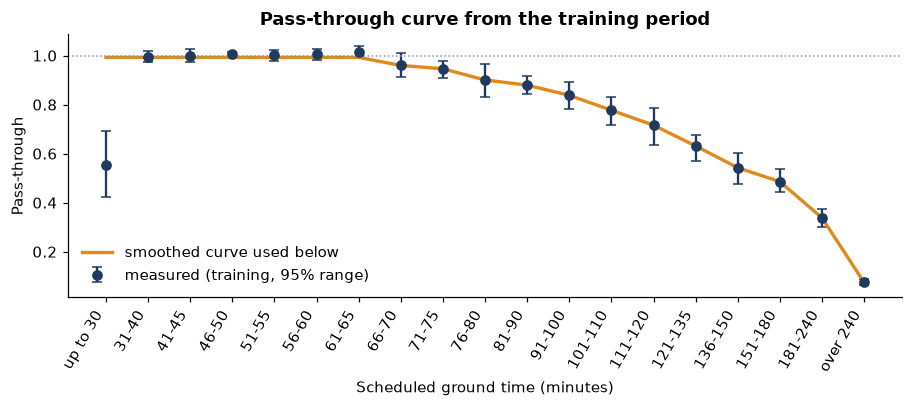

Pass-through at 45 / 65 / 90 / 120 / 180 minutes: [0.99, 0.98, 0.86, 0.68, 0.43]


In [5]:
fig, ax = plt.subplots(figsize=(8.4, 3.8))
x = np.arange(len(raw))
ax.errorbar(x, raw.slope, yerr=[raw.slope - raw.lo, raw.hi - raw.slope], fmt="o", color=BLUE, capsize=3, label="measured (training, 95% range)")
ax.plot(x, raw.smooth, color=ORANGE, lw=2.2, label="smoothed curve used below")
ax.set_xticks(x); ax.set_xticklabels(raw.group, rotation=60, ha="right"); ax.axhline(1, color=GREY, ls=":", lw=1)
ax.set_xlabel("Scheduled ground time (minutes)"); ax.set_ylabel("Pass-through"); ax.set_title("Pass-through curve from the training period"); ax.legend()
save(fig, "fig11_curve_used")
print("Pass-through at 45 / 65 / 90 / 120 / 180 minutes:", [round(float(pass_through(s)), 2) for s in [45, 65, 90, 120, 180]])

## 3. Predicting where inbound delay will be (Model B)

To decide *before the day* where buffer will be needed, the engine needs a forecast of the inbound delay of each turnaround. This is Model B from notebook 05:
a gradient-boosted tree model (LightGBM) using only timetable facts. It is trained on the training period and its tuning is checked on the validation period.
**It never sees the test period.**

In [6]:
import lightgbm as lgb
FEATS = ["Month", "DayOfWeek", "hr", "sg", "Distance", "prev_dist", "legno", "mins_since_first", "prev_dep_hr", "prev_arr_hr", "station", "prev_origin"]
T["Apos"] = T.A.clip(lower=0)
tr, va = T[T.split == "train"], T[T.split == "validate"]
te = T[T.split == "test"].sort_values("FlightDate").reset_index(drop=True)
regB = lgb.LGBMRegressor(n_estimators=1500, learning_rate=0.05, num_leaves=63, min_child_samples=200, subsample=0.8, subsample_freq=1,
                         colsample_bytree=0.8, reg_lambda=1.0, random_state=SEED, verbose=-1)
regB.fit(tr[FEATS], tr.Apos, eval_set=[(va[FEATS], va.Apos)], eval_metric="l1", callbacks=[lgb.early_stopping(50, verbose=False)])
te["risk"] = regB.predict(te[FEATS])
rho = float(pd.Series(te.risk.values).rank().corr(pd.Series(te.Apos.values).rank()))
print(f"Model B stopped at {regB.best_iteration_} trees. On the test period, rank correlation between predicted and actual inbound delay: {rho:.2f}")
print(f"Test turnarounds: {len(te):,} on {te.FlightDate.nunique()} days ({int(te.storm.sum()):,} turnarounds on {te[te.storm].FlightDate.nunique()} disruption days)")
RESULTS["model_B_rank_corr_test"] = rho

Model B stopped at 241 trees. On the test period, rank correlation between predicted and actual inbound delay: 0.31
Test turnarounds: 425,272 on 243 days (17,030 turnarounds on 16 disruption days)


## 4. The simulator

**How a day is replayed.**
1. The day's budget is the chosen average number of extra minutes times the number of turnarounds that day.
2. Each strategy decides, using only timetable facts and the training-period curve, how many extra minutes (up to **30** per turnaround) each turnaround gets. Every strategy spends the same budget.
3. We then take what really happened: for each turnaround, the real inbound delay `A`. The delay absorbed by the extra minutes `b` is
   `A x [ pass-through(ground time) - pass-through(ground time + b) ]` (using the curve).
4. We add this up over the whole test period, with and without disruption days.

**Fairness.** No strategy sees the real inbound delay, except the Hindsight line, which is only a ceiling for comparison. The curve and Model B come from earlier months than the test period.

In [7]:
BMAX = 30
SIZES = np.arange(0, BMAX + 1, 5)                     # extra minutes a turnaround can get: 0, 5, 10, ... 30
sg, apos, risk, dr = te.sg.values, te.Apos.values, te.risk.values, te.D_raw.values
p0 = pass_through(sg)
P_OPT = np.column_stack([pass_through(sg + o) for o in SIZES])       # pass-through after adding each amount
days, first = np.unique(te.FlightDate.values, return_index=True)
bounds = list(first) + [len(te)]
storm_i = te.storm.values; hub_i = te.hub.values == 1
POLICIES = ["No buffer", "Spread evenly", "Shortest first", "Riskiest first", "Engine (our method)", "Hindsight (not possible)"]

def allocate_day(policy, lo, hi, budget):
    n = hi - lo; b = np.zeros(n)
    if policy == "No buffer" or budget <= 0: return b
    if policy == "Spread evenly":
        return np.full(n, min(budget / n, BMAX))
    if policy in ("Shortest first", "Riskiest first"):
        order = np.argsort(sg[lo:hi], kind="stable") if policy == "Shortest first" else np.argsort(-risk[lo:hi], kind="stable")
        k = int(budget // BMAX); k = min(k, n)
        b[order[:k]] = BMAX
        if k < n: b[order[k]] = min(budget - k * BMAX, BMAX)
        return b
    r = risk[lo:hi] if policy == "Engine (our method)" else apos[lo:hi]
    G = r[:, None] * (p0[lo:hi, None] - P_OPT[lo:hi])               # delay minutes absorbed if the turnaround gets 0, 5, ... 30 extra minutes
    rows_ = np.arange(n)
    # step 1: find the "price per minute" (lam) at which the turnarounds' own best choices just fit the budget
    lam_lo, lam_hi = 0.0, float(G.max() / SIZES[1]) + 1.0
    for _ in range(40):
        lam = (lam_lo + lam_hi) / 2
        if SIZES[(G - lam * SIZES[None, :]).argmax(axis=1)].sum() > budget: lam_lo = lam
        else: lam_hi = lam
    k = (G - lam_hi * SIZES[None, :]).argmax(axis=1); spent = float(SIZES[k].sum())
    # step 2: spend what is left, in rounds, always on the best remaining upgrade
    for _ in range(14):
        dG = G - G[rows_, k][:, None]; dS = SIZES[None, :] - SIZES[k][:, None]
        ratio = np.where(dS > 0, dG / np.where(dS > 0, dS, 1), -np.inf)   # absorbed minutes per extra minute spent, for every possible upgrade
        j = ratio.argmax(axis=1); rr = ratio[rows_, j]
        cand = np.where(rr > 1e-12)[0]
        if len(cand) == 0: break
        order = cand[np.argsort(-rr[cand], kind="stable")]
        cost = (SIZES[j] - SIZES[k])[order]
        take = order[np.cumsum(cost) <= budget - spent]
        if len(take) == 0: break
        spent += cost[:len(take)].sum(); k[take] = j[take]
    b[:] = SIZES[k]
    return b

def run(policy, b0):
    b = np.zeros(len(te))
    for lo, hi in zip(bounds[:-1], bounds[1:]):
        b[lo:hi] = allocate_day(policy, lo, hi, b0 * (hi - lo))
    return b

def evaluate(b, pass_fn=pass_through):
    """Delay minutes absorbed, per turnaround, when each turnaround gets b extra minutes."""
    return apos * (pass_fn(sg) - pass_fn(sg + b))

def summarise(b, absorbed, mask=None):
    m = np.ones(len(te), bool) if mask is None else mask
    base_pass = (apos * p0)[m].sum()
    return dict(turnarounds=int(m.sum()), added_min=float(b[m].sum()), absorbed_min=float(absorbed[m].sum()),
                pct_removed=float(100 * absorbed[m].sum() / base_pass), absorbed_per_100_added=float(100 * absorbed[m].sum() / max(b[m].sum(), 1e-9)),
                late_avoided_per_1000=float(1000 * ((dr[m] >= 15) & (dr[m] - absorbed[m] < 15)).sum() / m.sum()))

BUDGETS = [2, 5, 10, 15]
SIM = {}                      # (policy, budget) -> dict(b, absorbed, daily)
for b0 in BUDGETS:
    for pol in POLICIES:
        b = run(pol, b0); a = evaluate(b)
        SIM[(pol, b0)] = dict(b=b, absorbed=a, daily=np.add.reduceat(a, first), added_daily=np.add.reduceat(b, first))
print("Simulation finished:", len(SIM), "runs over", len(days), "days.")

Simulation finished: 24 runs over 243 days.


## 5. Results at the main budget (5 extra minutes per turnaround, on average)

The table has one row per strategy. **Read it like this:**
* **Absorbed minutes**: delay minutes that were *not* passed on. Bigger is better.
* **% of passed-on delay removed**: the same, as a share of all the delay that is passed on without buffer.
* **Absorbed per 100 buffer minutes**: how hard each minute of buffer works. This is the fairest single comparison.
* **Late departures avoided per 1,000 turnarounds**: how many outbound flights that would have left 15 or more minutes late would now leave on time (or less than 15 late).

In [8]:
MAIN = 5
def table(mask, label):
    rows = []
    for pol in POLICIES:
        s = SIM[(pol, MAIN)]; r = summarise(s["b"], s["absorbed"], mask); r["strategy"] = pol; r["days"] = label; rows.append(r)
    return pd.DataFrame(rows)
tab_all, tab_norm, tab_storm = table(None, "all days"), table(~storm_i, "normal days"), table(storm_i, "disruption days")
show = lambda t: t.set_index("strategy")[["added_min", "absorbed_min", "pct_removed", "absorbed_per_100_added", "late_avoided_per_1000"]].round(1).rename(columns={
    "added_min": "buffer added (min)", "absorbed_min": "absorbed (min)", "pct_removed": "% of passed-on delay removed",
    "absorbed_per_100_added": "absorbed per 100 buffer min", "late_avoided_per_1000": "late departures avoided per 1,000"})
say("**All test days**"); display(show(tab_all))
say("**Normal days only (without the 27 disruption days)**"); display(show(tab_norm))
say("**Disruption days only**"); display(show(tab_storm))
RESULTS["main_budget"] = MAIN
RESULTS["table_all"] = tab_all.to_dict(orient="records"); RESULTS["table_normal"] = tab_norm.to_dict(orient="records"); RESULTS["table_storm"] = tab_storm.to_dict(orient="records")

**All test days**

,buffer added (min),absorbed (min),% of passed-on delay removed,absorbed per 100 buffer min,"late departures avoided per 1,000"
strategy,,,,,
No buffer,0.0,0.0,0.0,0.0,0.0
Spread evenly,2126360.0,67189.7,1.3,3.2,2.8
Shortest first,2126360.0,41928.9,0.8,2.0,0.9
Riskiest first,2126360.0,223325.6,4.4,10.5,4.1
Engine (our method),2124190.0,271116.5,5.3,12.8,5.5
Hindsight (not possible),2123980.0,536229.4,10.6,25.2,9.1


**Normal days only (without the 27 disruption days)**

,buffer added (min),absorbed (min),% of passed-on delay removed,absorbed per 100 buffer min,"late departures avoided per 1,000"
strategy,,,,,
No buffer,0.0,0.0,0.0,0.0,0.0
Spread evenly,2041210.0,62447.4,1.3,3.1,2.8
Shortest first,2041210.0,38930.3,0.8,1.9,0.8
Riskiest first,2041210.0,209920.9,4.4,10.3,4.1
Engine (our method),2039125.0,253641.2,5.4,12.4,5.5
Hindsight (not possible),2038945.0,503159.0,10.7,24.7,9.2


**Disruption days only**

,buffer added (min),absorbed (min),% of passed-on delay removed,absorbed per 100 buffer min,"late departures avoided per 1,000"
strategy,,,,,
No buffer,0.0,0.0,0.0,0.0,0.0
Spread evenly,85150.0,4742.4,1.3,5.6,3.2
Shortest first,85150.0,2998.5,0.8,3.5,1.1
Riskiest first,85150.0,13404.6,3.8,15.7,4.1
Engine (our method),85065.0,17475.3,5.0,20.5,6.0
Hindsight (not possible),85035.0,33070.4,9.4,38.9,7.5


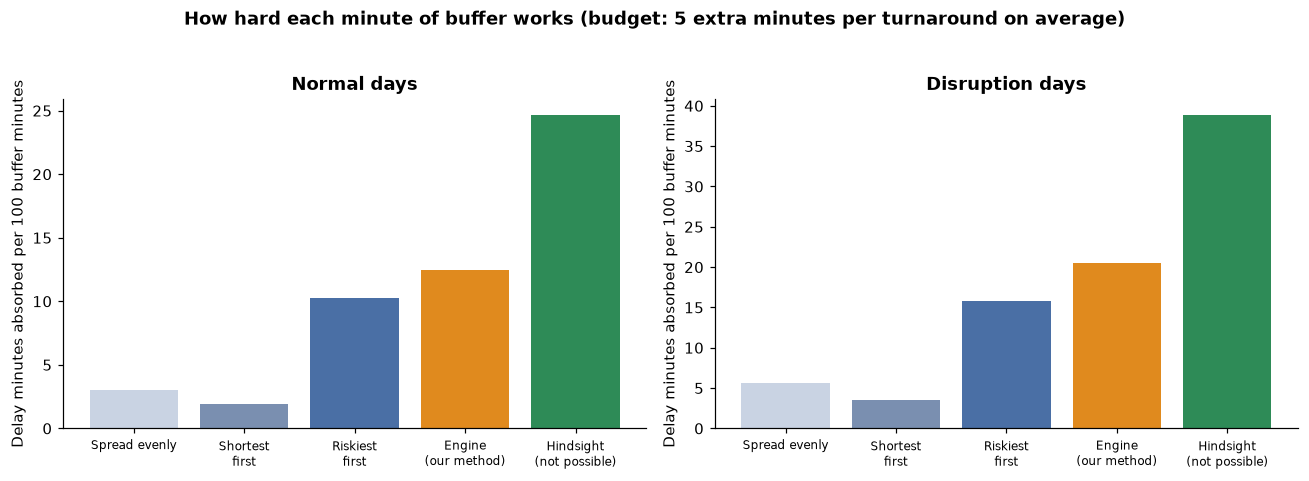

**What we see (all test days, 5 extra minutes per turnaround on average).**
* **Spread evenly** absorbs **67,190 delay minutes**, which is **1.3%** of the delay passed on without buffer; each 100 buffer minutes absorb **3**.
* **The engine** absorbs **271,117** (**5.3%**); each 100 buffer minutes absorb **13**. That is **4.0 times** the absorbed minutes of spreading evenly for the same budget.
* **Hindsight ceiling:** 536,229 minutes. The engine reaches **51%** of what is possible with perfect knowledge.
* The simple rules do worse: shortest first absorbs 41,929 and riskiest first 223,326.
* On **normal days** the engine absorbs 12 per 100 buffer minutes against 3 for even spreading; on **disruption days** 21 against 6.

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
cols = [GREY, LIGHT, "#7A8FB0", "#4A6FA5", ORANGE, GREEN]
for a_, (t, ttl) in zip(ax, [(tab_norm, "Normal days"), (tab_storm, "Disruption days")]):
    t = t[t.strategy != "No buffer"]
    a_.bar(range(len(t)), t.absorbed_per_100_added, color=cols[1:])
    a_.set_xticks(range(len(t))); a_.set_xticklabels([s.replace(" (", "\n(") .replace(" first", "\nfirst") for s in t.strategy], fontsize=8)
    a_.set_ylabel("Delay minutes absorbed per 100 buffer minutes"); a_.set_title(ttl)
fig.suptitle("How hard each minute of buffer works (budget: 5 extra minutes per turnaround on average)", fontweight="bold", y=1.03)
save(fig, "fig12_efficiency_by_strategy")

def get(t, pol, col): return float(t.set_index("strategy").loc[pol, col])
E_, U_ = "Engine (our method)", "Spread evenly"
gain_x = get(tab_all, E_, "absorbed_min") / get(tab_all, U_, "absorbed_min")
RESULTS["engine_vs_uniform_all"] = gain_x
say(f"""**What we see (all test days, 5 extra minutes per turnaround on average).**
* **Spread evenly** absorbs **{get(tab_all, U_, 'absorbed_min'):,.0f} delay minutes**, which is **{get(tab_all, U_, 'pct_removed'):.1f}%** of the delay passed on without buffer; each 100 buffer minutes absorb **{get(tab_all, U_, 'absorbed_per_100_added'):.0f}**.
* **The engine** absorbs **{get(tab_all, E_, 'absorbed_min'):,.0f}** (**{get(tab_all, E_, 'pct_removed'):.1f}%**); each 100 buffer minutes absorb **{get(tab_all, E_, 'absorbed_per_100_added'):.0f}**. That is **{gain_x:.1f} times** the absorbed minutes of spreading evenly for the same budget.
* **Hindsight ceiling:** {get(tab_all, 'Hindsight (not possible)', 'absorbed_min'):,.0f} minutes. The engine reaches **{100*get(tab_all, E_, 'absorbed_min')/get(tab_all, 'Hindsight (not possible)', 'absorbed_min'):.0f}%** of what is possible with perfect knowledge.
* The simple rules do worse: shortest first absorbs {get(tab_all, 'Shortest first', 'absorbed_min'):,.0f} and riskiest first {get(tab_all, 'Riskiest first', 'absorbed_min'):,.0f}.
* On **normal days** the engine absorbs {get(tab_norm, E_, 'absorbed_per_100_added'):.0f} per 100 buffer minutes against {get(tab_norm, U_, 'absorbed_per_100_added'):.0f} for even spreading; on **disruption days** {get(tab_storm, E_, 'absorbed_per_100_added'):.0f} against {get(tab_storm, U_, 'absorbed_per_100_added'):.0f}.""")

## 6. How sure are we? A 95% range for the engine's advantage

The test period has 243 days, and some days (storms) are far worse than others, so a single total could be driven by a few days. We re-draw whole days at random 2,000 times
and recompute **how many times more delay the engine absorbs than each other strategy**. If the 95% range stays above 1.0, the engine is better in almost every re-draw.

In [10]:
rng = np.random.default_rng(SEED); nd = len(days); B = 2000
idx = rng.integers(0, nd, size=(B, nd))
def ratio_ci(pol_a, pol_b, b0=MAIN):
    a = SIM[(pol_a, b0)]["daily"]; b = SIM[(pol_b, b0)]["daily"]
    r = a[idx].sum(axis=1) / b[idx].sum(axis=1)
    return float(a.sum() / b.sum()), float(np.percentile(r, 2.5)), float(np.percentile(r, 97.5))
rows = []
for other in ["Spread evenly", "Shortest first", "Riskiest first"]:
    for b0 in BUDGETS:
        pt, lo, hi = ratio_ci("Engine (our method)", other, b0)
        rows.append(dict(compared_with=other, budget_min_per_turnaround=b0, engine_vs_it=pt, low_95=lo, high_95=hi))
cit = pd.DataFrame(rows); display(cit.round(2).set_index(["compared_with", "budget_min_per_turnaround"]))
RESULTS["engine_ratio_ci"] = rows
us = cit[cit.compared_with == "Spread evenly"].set_index("budget_min_per_turnaround")
say(f"""**What we see.** Against **spreading evenly**, the engine absorbs {us.loc[2,'engine_vs_it']:.1f}x / {us.loc[5,'engine_vs_it']:.1f}x / {us.loc[10,'engine_vs_it']:.1f}x / {us.loc[15,'engine_vs_it']:.1f}x as much for budgets of 2 / 5 / 10 / 15 minutes per turnaround.
At the main budget the 95% range is **{us.loc[5,'low_95']:.1f}x to {us.loc[5,'high_95']:.1f}x**. {"The range stays above 1.0 in every case, so the engine's advantage does not depend on a few lucky days." if (cit.low_95 > 1).all() else "In at least one case the range reaches down to 1.0 or lower, so the advantage there is not certain."}""")

engine_vs_it  low_95  high_95
compared_with  budget_min_per_turnaround                               
Spread evenly  2                                  5.89    5.76     6.02
               5                                  4.04    3.96     4.11
               10                                 2.85    2.81     2.88
               15                                 2.03    2.02     2.05
Shortest first 2                                 25.38   22.78    28.50
               5                                  6.47    6.18     6.77
               10                                 2.89    2.82     2.96
               15                                 2.13    2.10     2.16
Riskiest first 2                                  1.38    1.35     1.40
               5                                  1.21    1.20     1.23
               10                                 1.13    1.13     1.14
               15                                 1.08    1.08     1.09

**What we see.** Against **spreading evenly**, the engine absorbs 5.9x / 4.0x / 2.8x / 2.0x as much for budgets of 2 / 5 / 10 / 15 minutes per turnaround.
At the main budget the 95% range is **4.0x to 4.1x**. The range stays above 1.0 in every case, so the engine's advantage does not depend on a few lucky days.

## 7. How does the answer change with the size of the budget?

If the budget is tiny, only the very best places get buffer. If it is large, even weak places get some. **What to look for:** does the engine stay ahead at every size? Do the curves flatten (a sign of diminishing returns)?

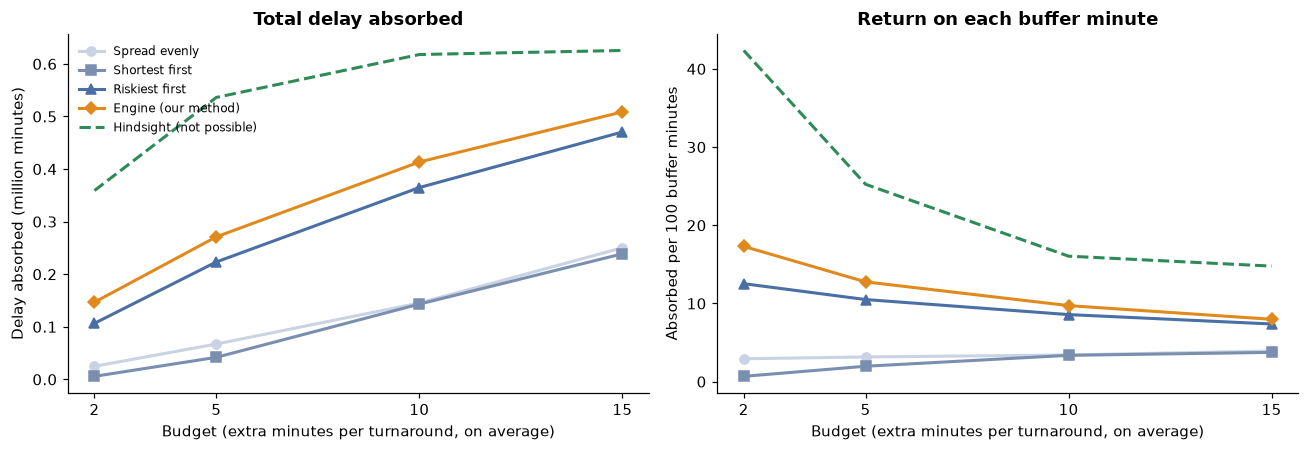

budget,2,5,10,15
absorbed per 100 buffer min,,,,
No buffer,0.0,0.0,0.0,0.0
Spread evenly,2.9,3.2,3.4,3.9
Shortest first,0.7,2.0,3.4,3.7
Riskiest first,12.5,10.5,8.6,7.4
Engine (our method),17.3,12.8,9.7,8.0
Hindsight (not possible),42.4,25.2,16.0,14.8


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
sty = {"Spread evenly": (LIGHT, "o-"), "Shortest first": ("#7A8FB0", "s-"), "Riskiest first": ("#4A6FA5", "^-"), "Engine (our method)": (ORANGE, "D-"), "Hindsight (not possible)": (GREEN, "--")}
for pol, (c, m) in sty.items():
    ax[0].plot(BUDGETS, [SIM[(pol, b0)]["absorbed"].sum() / 1e6 for b0 in BUDGETS], m, color=c, label=pol, lw=2)
    ax[1].plot(BUDGETS, [100 * SIM[(pol, b0)]["absorbed"].sum() / SIM[(pol, b0)]["added_daily"].sum() for b0 in BUDGETS], m, color=c, label=pol, lw=2)
ax[0].set_xlabel("Budget (extra minutes per turnaround, on average)"); ax[0].set_ylabel("Delay absorbed (million minutes)"); ax[0].set_title("Total delay absorbed"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("Budget (extra minutes per turnaround, on average)"); ax[1].set_ylabel("Absorbed per 100 buffer minutes"); ax[1].set_title("Return on each buffer minute")
ax[0].set_xticks(BUDGETS); ax[1].set_xticks(BUDGETS)
save(fig, "fig13_budget_sweep")
sweep = pd.DataFrame([{**summarise(SIM[(p, b0)]["b"], SIM[(p, b0)]["absorbed"]), "strategy": p, "budget": b0} for p in POLICIES for b0 in BUDGETS])
RESULTS["sweep"] = sweep.to_dict(orient="records")
display(sweep.pivot(index="strategy", columns="budget", values="absorbed_per_100_added").loc[POLICIES].round(1).rename_axis("absorbed per 100 buffer min"))

## 8. Where does the engine put the buffer?

A rule is only believable if its choices make sense. We look at where the extra minutes go, compared with spreading evenly.

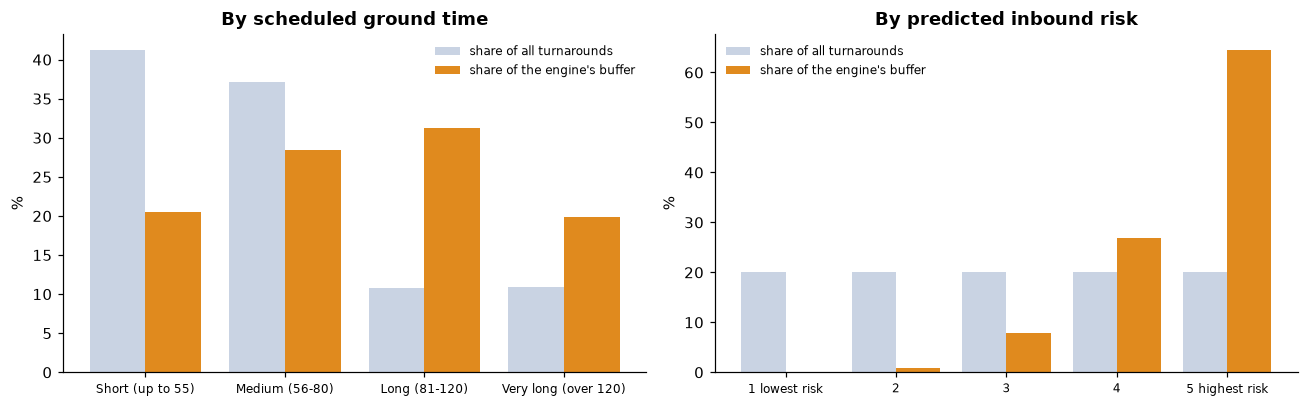

,share of engine buffer (%),share of all turnarounds (%)
by,,
Short (up to 55),20.5,41.2
Medium (56-80),28.4,37.1
Long (81-120),31.2,10.7
Very long (over 120),19.9,10.9


,share of engine buffer (%),share of all turnarounds (%)
by,,
1 lowest risk,0.0,20.0
2,0.8,20.0
3,7.9,20.0
4,26.9,20.0
5 highest risk,64.4,20.0


**What we see.** The engine gives **20%** of its buffer to short turnarounds (up to 55 min) although they are 41% of all turnarounds, and **51%** to turnarounds that are already longer than 80 minutes (22% of turnarounds).
By risk, the highest-risk fifth receives **64%** of the buffer and the lowest-risk fifth **0%**. The ten busiest airports get **69%** of the buffer (65% of turnarounds).
This matches notebook 04: minutes added to turnarounds that are too short are mostly wasted, and buffer pays off where a turnaround is long enough to absorb and the inbound flight is likely to be late.

In [12]:
eng_b = SIM[("Engine (our method)", MAIN)]["b"]
band = pd.cut(sg, [0, 55, 80, 120, 100000], labels=["Short (up to 55)", "Medium (56-80)", "Long (81-120)", "Very long (over 120)"])
rk = pd.qcut(risk, 5, labels=["1 lowest risk", "2", "3", "4", "5 highest risk"])
def share(by):
    d_ = pd.DataFrame({"by": by, "engine": eng_b, "even": SIM[("Spread evenly", MAIN)]["b"], "n": 1})
    g_ = d_.groupby("by", observed=True)[["engine", "even", "n"]].sum()
    return 100 * g_ / g_.sum()
s1, s2 = share(band), share(rk)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a_, s_, ttl in [(ax[0], s1, "By scheduled ground time"), (ax[1], s2, "By predicted inbound risk")]:
    x = np.arange(len(s_)); a_.bar(x - 0.2, s_["n"], 0.4, color=LIGHT, label="share of all turnarounds"); a_.bar(x + 0.2, s_["engine"], 0.4, color=ORANGE, label="share of the engine's buffer")
    a_.set_xticks(x); a_.set_xticklabels(s_.index, fontsize=8); a_.set_ylabel("%"); a_.set_title(ttl); a_.legend(fontsize=8)
save(fig, "fig14_where_buffer_goes")
display(pd.concat({"share of engine buffer (%)": s1.engine, "share of all turnarounds (%)": s1.n}, axis=1).round(1))
display(pd.concat({"share of engine buffer (%)": s2.engine, "share of all turnarounds (%)": s2.n}, axis=1).round(1))
hubs = float(eng_b[hub_i].sum() / eng_b.sum()); hubs_all = float(hub_i.mean())
RESULTS["where"] = dict(by_band=s1.round(2).to_dict(), by_risk=s2.round(2).to_dict(), hub_share_of_buffer=hubs, hub_share_of_turnarounds=hubs_all)
say(f"""**What we see.** The engine gives **{s1.engine.iloc[0]:.0f}%** of its buffer to short turnarounds (up to 55 min) although they are {s1.n.iloc[0]:.0f}% of all turnarounds, and **{s1.engine.iloc[2] + s1.engine.iloc[3]:.0f}%** to turnarounds that are already longer than 80 minutes ({s1.n.iloc[2] + s1.n.iloc[3]:.0f}% of turnarounds).
By risk, the highest-risk fifth receives **{s2.engine.iloc[-1]:.0f}%** of the buffer and the lowest-risk fifth **{s2.engine.iloc[0]:.0f}%**. The ten busiest airports get **{100*hubs:.0f}%** of the buffer ({100*hubs_all:.0f}% of turnarounds).
This matches notebook 04: minutes added to turnarounds that are too short are mostly wasted, and buffer pays off where a turnaround is long enough to absorb and the inbound flight is likely to be late.""")

## 9. Stress tests: is the result an artefact of our assumptions?

Two things could make the result look better than it is, so we test both.

1. **The curve drifts.** We allocated with the curve learned in 2025. What if the pass-through in 2026 is different? We re-measure the curve **on the test period itself** (hindsight, only for this check) and score the *same* allocations with it.
2. **The curve over-states what buffer can do.** The curve shows association, and some of the drop at long ground times comes from how the airline plans its flights, not from the minutes themselves. We therefore also score the allocations as if **absorption starts 15 minutes later** than measured, which is a harsher curve for exactly the turnarounds the engine likes to pick. (Simply halving all absorption would shrink every strategy equally and cannot change the ranking, so it would not be a real test.)

In [13]:
Pte = te[te.Apos > 0].copy(); Pte["A"] = Pte.A; Pte["sgb"] = pd.cut(Pte.sg, EDGES, labels=False)
raw_te = slope_table(Pte, "sgb", BIN_LABELS, B=1)
bs_te = Pte.groupby("sgb").sg.mean().reindex(range(len(BIN_LABELS)))
ok_t = raw_te.slope.notna().values
iso_te = IsotonicRegression(increasing=False, y_min=0.0, y_max=1.0, out_of_bounds="clip").fit(bs_te[ok_t], raw_te.slope[ok_t], sample_weight=raw_te.n[ok_t])
def pass_te(x):
    z = np.atleast_1d(np.asarray(x, dtype=float)); y = iso_te.predict(z); return y if np.ndim(x) else float(y[0])
def pass_late(x):                       # absorption starts 15 minutes later than measured
    return pass_through(np.maximum(np.asarray(x, dtype=float) - 15, 0)) if np.ndim(x) else float(pass_through(max(x - 15, 0)))

rows = []
for label, fn in [("Curve from 2025 (as allocated)", pass_through), ("Curve re-measured on the test period", pass_te), ("Absorption starts 15 minutes later", pass_late)]:
    res = {}
    for pol in ["Spread evenly", "Riskiest first", "Engine (our method)"]:
        s = SIM[(pol, MAIN)]; a = evaluate(s["b"], fn); res[pol] = a.sum()
    rows.append(dict(scenario=label, spread_evenly=res["Spread evenly"], riskiest_first=res["Riskiest first"], engine=res["Engine (our method)"], engine_vs_even=res["Engine (our method)"] / res["Spread evenly"],
                     engine_vs_riskiest=res["Engine (our method)"] / res["Riskiest first"]))
stress = pd.DataFrame(rows); display(stress.round(2).set_index("scenario")); RESULTS["stress"] = rows
say(f"""**What we see.** If the pass-through of 2026 is measured on the test period itself, the engine still absorbs **{stress.engine_vs_even.iloc[1]:.1f} times** as much as spreading evenly (against {stress.engine_vs_even.iloc[0]:.1f} with the 2025 curve).
If absorption starts 15 minutes later than measured, the engine still absorbs **{stress.engine_vs_even.iloc[2]:.1f} times** as much as spreading evenly and **{stress.engine_vs_riskiest.iloc[2]:.2f} times** as much as riskiest first (totals: {stress.engine.iloc[2]:,.0f} against {stress.engine.iloc[0]:,.0f} minutes).
{"The ranking of strategies does not change in either test." if (stress.engine_vs_even > 1).all() and (stress.engine_vs_riskiest > 1).all() else "In at least one test the engine loses its lead over a simpler rule, so the conclusion needs care."}
So the **ranking** of strategies is more trustworthy than the **absolute** minutes, which are upper bounds.""")

,spread_evenly,riskiest_first,engine,engine_vs_even,engine_vs_riskiest
scenario,,,,,
Curve from 2025 (as allocated),67189.74,223325.58,271116.55,4.04,1.21
Curve re-measured on the test period,72153.59,228574.73,266811.84,3.70,1.17
Absorption starts 15 minutes later,45666.88,172659.62,203441.18,4.45,1.18


**What we see.** If the pass-through of 2026 is measured on the test period itself, the engine still absorbs **3.7 times** as much as spreading evenly (against 4.0 with the 2025 curve).
If absorption starts 15 minutes later than measured, the engine still absorbs **4.5 times** as much as spreading evenly and **1.18 times** as much as riskiest first (totals: 203,441 against 271,117 minutes).
The ranking of strategies does not change in either test.
So the **ranking** of strategies is more trustworthy than the **absolute** minutes, which are upper bounds.

## 10. Summary of notebook 06, with its limits

In [14]:
us5 = cit[(cit.compared_with == "Spread evenly") & (cit.budget_min_per_turnaround == 5)].iloc[0]
rk5 = cit[(cit.compared_with == "Riskiest first") & (cit.budget_min_per_turnaround == 5)].iloc[0]
rk15 = cit[(cit.compared_with == "Riskiest first") & (cit.budget_min_per_turnaround == 15)].iloc[0]
say(f"""**Answer to the business question** (test period Jan to Aug 2026, budget of 5 extra minutes per turnaround on average):

1. **Where the engine puts buffer matters a lot, but buffer alone is a small lever.** For the same budget it absorbs **{gain_x:.1f} times** as much delay as spreading buffer evenly (95% range {us5.low_95:.1f}x to {us5.high_95:.1f}x), and reaches **{100*get(tab_all, E_, 'absorbed_min')/get(tab_all, 'Hindsight (not possible)', 'absorbed_min'):.0f}%** of the ceiling set by perfect knowledge. Even so, it removes only **{get(tab_all, E_, 'pct_removed'):.1f}%** of the delay that is passed on, because 5 minutes per turnaround is a small budget against a large amount of delay (see Section 7 for bigger budgets). The 95% range covers day-to-day variation only, not the modelling assumptions tested in Section 9.
2. **Compared with simple rules:** the engine absorbs {rk5.engine_vs_it:.2f} times as much as "riskiest first" at this budget (95% range {rk5.low_95:.2f} to {rk5.high_95:.2f}); {"at larger budgets the two are close" if abs(rk15.engine_vs_it-1)<0.15 else "see the table in Section 6 for how this changes with the budget"}. Putting buffer on the shortest turnarounds does worst, because minutes added there are mostly wasted.
3. **It also works on disruption days:** {get(tab_storm, E_, 'absorbed_per_100_added'):.0f} minutes absorbed per 100 buffer minutes against {get(tab_storm, U_, 'absorbed_per_100_added'):.0f} for even spreading.
4. **It does not depend on one assumption:** the ranking holds when the curve is re-measured on the test period and when absorption is assumed to start 15 minutes later than measured.

**Limits, stated plainly:**
* **Association, not cause.** The curve is measured from how delay behaved, not from an experiment in which buffer was added. The absorbed minutes are upper bounds; the ranking of strategies is more reliable than the totals.
* **Buffer is not free in real life.** Extra ground time costs aircraft time and can shift later flights. We compare strategies at the *same* total budget but do not price the cost of the minutes.
* **The simulator replays the past.** We cannot test how the airline would react to a new schedule, or whether the aircraft assignments would stay the same.
* **Only turnarounds where both flights operated.** Cancellation chains are not part of the simulation.
* **One airline, 20 months.** The curve and the risk model come from 2025 and are applied to 2026, which is a fair future test but covers each season only once or twice.""")
write_results("results_06_simulator.json")

**Answer to the business question** (test period Jan to Aug 2026, budget of 5 extra minutes per turnaround on average):

1. **Where the engine puts buffer matters a lot, but buffer alone is a small lever.** For the same budget it absorbs **4.0 times** as much delay as spreading buffer evenly (95% range 4.0x to 4.1x), and reaches **51%** of the ceiling set by perfect knowledge. Even so, it removes only **5.3%** of the delay that is passed on, because 5 minutes per turnaround is a small budget against a large amount of delay (see Section 7 for bigger budgets). The 95% range covers day-to-day variation only, not the modelling assumptions tested in Section 9.
2. **Compared with simple rules:** the engine absorbs 1.21 times as much as "riskiest first" at this budget (95% range 1.20 to 1.23); at larger budgets the two are close. Putting buffer on the shortest turnarounds does worst, because minutes added there are mostly wasted.
3. **It also works on disruption days:** 21 minutes absorbed per 100 buffer minutes against 6 for even spreading.
4. **It does not depend on one assumption:** the ranking holds when the curve is re-measured on the test period and when absorption is assumed to start 15 minutes later than measured.

**Limits, stated plainly:**
* **Association, not cause.** The curve is measured from how delay behaved, not from an experiment in which buffer was added. The absorbed minutes are upper bounds; the ranking of strategies is more reliable than the totals.
* **Buffer is not free in real life.** Extra ground time costs aircraft time and can shift later flights. We compare strategies at the *same* total budget but do not price the cost of the minutes.
* **The simulator replays the past.** We cannot test how the airline would react to a new schedule, or whether the aircraft assignments would stay the same.
* **Only turnarounds where both flights operated.** Cancellation chains are not part of the simulation.
* **One airline, 20 months.** The curve and the risk model come from 2025 and are applied to 2026, which is a fair future test but covers each season only once or twice.

Saved results_06_simulator.json and 11 chart files in the folder 'modelling_outputs'.
